### Beyond mean pooling: temporal, spatial-spread, prompted-readout and attention (MIL) features, ego and exo

So far each take was one vector: zero-shot Qwen3.5-4B hidden states averaged over all the video tokens of a 20 s
1 FPS window, then over the take's windows. Every way of supervising that vector reached the same ceiling (about 0.35
within-scenario Spearman with proficiency level), and the exo view helped some scenarios and hurt others
(`exo_8fps.ipynb`). Here the pooling changes, for the ego and the exo (best_exo) tiles, from one new forward pass per
window whose prompt is the video followed by a fixed question ("How skilled is the person in this <activity> video?
Reply with exactly one word: beginner, intermediate, advanced, or expert."):

| representation | what it keeps |
|---|---|
| **mean** | the earlier features (reproduced exactly: the question comes after the video and attention is causal) |
| **temporal std** | per-dimension spread of the 2 s time steps over the take (space pooled only) |
| **motion** | RMS change between consecutive time steps within a window |
| **token std** | per-dimension spread over a window's video tokens (space and time), averaged over windows |
| **readout** | the last prompt token's hidden state: the model's own attention over the video, steered by the question |
| **zero-shot answer** | the model's probabilities for the four answers (also scored with no fitting at all) |
| **MIL attention** | a learned attention over a take's windows (score per window, softmax, weighted mean), vs the same model with uniform weights |

and **ego + exo**: both views' blocks side by side.

Evaluation as before: 4 x 5-fold CV split by participant over the 1,338 takes (the same folds); every block is
scenario-centered and reduced to 64 PCA dimensions inside the fold; logistic regression for 4-class accuracy and ridge
regression for the ordinal within-scenario Spearman (predictions centered within each fold and scenario);
participant-bootstrap intervals; scenario-only and duration-only controls.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import math
from concurrent.futures import ThreadPoolExecutor

import torch
from tqdm.auto import tqdm

# Richer zero-shot Qwen3.5-4B features of the 1 FPS tiles (back-to-back 20 s windows), ego and exo (best_exo), from one
# forward pass per window whose prompt is the video followed by a fixed skill question:
#   * "temporal": (t, hidden) per time step (2 frames), mean over that step's video tokens (space pooled only);
#   * "std":      (hidden,) standard deviation over all the window's video tokens;
#   * "readout":  (hidden,) the hidden state of the last prompt token, which attends to the video through the question;
#   * "answer":   (4,) log-probabilities of the answer options' first tokens, renormalised over the four options.
# Attention is causal and the question comes after the video, so the video tokens are exactly as in the earlier
# video-only extraction: mean(temporal) reproduces the cached pooled vectors (checked below).
EMBEDDING_DIR = Path("embeddings")
LAYERS = {"early": 8, "middle": 16, "last": 32}
EXO_SIZE = (576, 320)
WINDOW_FRAMES = 20
BATCH_WINDOWS = 4
ACTIVITY = {"Basketball": "basketball", "Cooking": "cooking", "Dance": "dance", "Music": "music (playing an instrument)",
            "Rock Climbing": "bouldering (rock climbing)", "Soccer": "soccer"}
OPTIONS = ["beginner", "intermediate", "advanced", "expert"]

def question(scenario):
    return (f"How skilled is the person in this {ACTIVITY[scenario]} video? "
            f"Reply with exactly one word: {', '.join(OPTIONS[:-1])}, or {OPTIONS[-1]}.")

TAKES_META = {t["take_name"]: t for t in json.loads((DATA_ROOT / "takes.json").read_text(encoding="utf-8"))}
EXO1_PATH = {}
for annotation_file in ("proficiency_demonstrator_train.json", "proficiency_demonstrator_val.json"):
    for m in json.loads((ANNOTATION_ROOT / annotation_file).read_text(encoding="utf-8"))["annotations"]:
        parts = m["video_paths"]["exo1"].split("/")
        parts[-1:-1] = ["downscaled", "448"]
        EXO1_PATH[take_name(m)] = DATA_ROOT.joinpath(*parts)

def exo_camera(take):
    best = TAKES_META[take].get("best_exo")
    path = DATA_ROOT / "takes" / take / "frame_aligned_videos" / "downscaled" / "448" / f"{best}.mp4"
    if best and path.exists():
        return best, path
    return "exo1 (no best_exo)", EXO1_PATH[take]

def tile_windows(take, length=WINDOW_FRAMES):
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

def decode(take, view):
    """(camera, (seconds, H, W, 3) frames 0, 30, 60, ...): ego at its 448x448, exo scaled to 576x320 (as before)."""
    camera, path = ("ego", Path(clip_of[take]["video"])) if view == "ego" else exo_camera(take)
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        stream.thread_type = "AUTO"
        step = round(float(stream.average_rate) / WINDOW_FPS)
        width, height = stream.codec_context.width, stream.codec_context.height
        size = {} if view == "ego" else dict(zip(("width", "height"), EXO_SIZE if width >= height else EXO_SIZE[::-1]),
                                               interpolation="BILINEAR")
        frames = [frame.to_ndarray(format="rgb24", **size) for i, frame in enumerate(container.decode(video=0)) if i % step == 0]
    return camera, np.stack(frames)

VIEWS = ("ego", "exo")
CACHE = {view: EMBEDDING_DIR / f"qwen35_base_{view}_tiles1fps_readout.pt" for view in VIEWS}
caches = {view: torch.load(CACHE[view]) if CACHE[view].exists() else {"camera": {}, "windows": {}} for view in VIEWS}
todo = [(take, view) for view in VIEWS for take in clip_of if take not in caches[view]["windows"]]
print(f"{len(todo)} (take, view) pairs to embed")

if todo:
    from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
    from transformers.video_utils import VideoMetadata

    model_id = "Qwen/Qwen3.5-4B"
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16,
                                    bnb_4bit_use_double_quant=True)
    model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
    processor = AutoProcessor.from_pretrained(model_id)
    processor.video_processor.cap_pixels_per_frame = False
    VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")
    OPTION_TOKENS = [processor.tokenizer.encode(o, add_special_tokens=False)[0] for o in OPTIONS]
    assert len(set(OPTION_TOKENS)) == len(OPTIONS), OPTION_TOKENS
    PROMPTS = {s: processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "video"}, {"type": "text", "text": question(s)}]}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False) for s in ACTIVITY}
    DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
    _state, _out = None, {}

    def _make_hook(layer):
        def hook(module, args, output):
            if _state is None:
                return
            hidden = (output[0] if isinstance(output, tuple) else output).float()
            mask, t = _state
            rows = []
            for b in range(hidden.shape[0]):
                video = hidden[b, mask[b]]
                rows.append((video.view(t, -1, video.shape[-1]).mean(1), video.std(0), hidden[b, -1]))
            _out[layer] = rows
        return hook

    for layer in LAYERS.values():
        DECODER_LAYERS[layer - 1].register_forward_hook(_make_hook(layer))

    @torch.inference_mode()
    def embed(frames, starts, length, scenario):
        """{start: {"temporal": (L, t, d), "std": (L, d), "readout": (L, d), "answer": (4,)}} (fp16 but answer)."""
        global _state
        metadata = VideoMetadata(total_num_frames=length * 30, fps=30.0, frames_indices=np.arange(length) * 30)
        out = {}
        for i in range(0, len(starts), BATCH_WINDOWS):
            chunk = starts[i:i + BATCH_WINDOWS]
            batch = processor(text=[PROMPTS[scenario]] * len(chunk), videos=[frames[s:s + length] for s in chunk],
                              video_metadata=[metadata] * len(chunk), do_sample_frames=False, return_tensors="pt")
            grid = batch["video_grid_thw"]
            assert (grid[:, 0] == length // 2).all() and bool(batch["attention_mask"].all()), grid
            t = length // 2
            _state = ((batch["input_ids"] == VIDEO_TOKEN_ID).to(model.device), t)
            _out.clear()
            try:
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    logits = model(**batch.to(model.device), logits_to_keep=1).logits[:, -1].float()
            finally:
                _state = None
            answer = torch.log_softmax(logits[:, OPTION_TOKENS], -1).cpu()
            for b, start in enumerate(chunk):
                parts = [_out[layer][b] for layer in LAYERS.values()]
                out[start] = {"temporal": torch.stack([p[0] for p in parts]).half().cpu(),
                              "std": torch.stack([p[1] for p in parts]).half().cpu(),
                              "readout": torch.stack([p[2] for p in parts]).half().cpu(),
                              "answer": answer[b]}
        return out

    with ThreadPoolExecutor(1) as pool:
        upcoming = pool.submit(decode, *todo[0])
        for k, (take, view) in enumerate(tqdm(todo, desc="take x view"), 1):
            camera, frames = upcoming.result()
            if k < len(todo):
                upcoming = pool.submit(decode, *todo[k])
            assert len(frames) >= clip_of[take]["seconds"] - 1, (take, view, len(frames), clip_of[take]["seconds"])
            by_length = defaultdict(list)
            for start, size in tile_windows(take):
                if start + size <= len(frames):
                    by_length[size].append(start)
            windows = {}
            for size, starts in by_length.items():
                for start, value in embed(frames, starts, size, clip_of[take]["scenario"]).items():
                    windows[start, size] = value
            caches[view]["windows"][take], caches[view]["camera"][take] = windows, camera
            if k % 100 == 0 or k == len(todo) or todo[k][1] != view:
                torch.save(caches[view], CACHE[view])
    del model
    torch.cuda.empty_cache()

# Check: the mean over time steps is the earlier video-only pooled vector of the same tile.
reference = {"ego": torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt"),
             "exo": torch.load(EMBEDDING_DIR / "qwen35_base_exo_tiles1fps.pt")["windows"]}
for view in VIEWS:
    cosines = [torch.nn.functional.cosine_similarity(w["temporal"].float().mean(1), reference[view][take][key].float(), -1)
               for take, windows in caches[view]["windows"].items() for key, w in windows.items()]
    cosines = torch.stack(cosines) if cosines else torch.zeros(1, 3)
    print(f"{view}: {len(caches[view]['windows'])} takes, {len(cosines)} tiles; cosine with the video-only means per layer: "
          f"min {cosines.min(0).values.numpy().round(4)}, mean {cosines.mean(0).numpy().round(5)}")

0 (take, view) pairs to embed


ego: 1338 takes, 7486 tiles; cosine with the video-only means per layer: min [1.     1.     0.9996], mean [1.      1.      0.99999]


exo: 1338 takes, 7486 tiles; cosine with the video-only means per layer: min [1.     1.     0.9999], mean [1.      1.      0.99997]


In [3]:
import gc

from scipy.stats import spearmanr

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
position = {name: i for i, name in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
LAYER_LIST = list(LAYERS.values())
BASE = ["mean", "temporal std", "motion", "token std", "readout"]

def take_features(windows):
    """Take-level blocks {rep: (L, d)}, the (L, n_windows, d) window means and the (n_windows, 4) answer log-probs."""
    ws = [windows[key] for key in sorted(windows)]
    temporal = [w["temporal"].float() for w in ws]
    steps = torch.cat(temporal, 1)
    diffs = [x[:, 1:] - x[:, :-1] for x in temporal if x.shape[1] > 1]
    zeros = torch.zeros_like(steps[:, 0])
    window_means = torch.stack([x.mean(1) for x in temporal], 1)
    blocks = {"mean": window_means.mean(1),
              "temporal std": steps.std(1) if steps.shape[1] > 1 else zeros,
              "motion": torch.cat(diffs, 1).pow(2).mean(1).sqrt() if diffs else zeros,
              "token std": torch.stack([w["std"].float() for w in ws]).mean(0),
              "readout": torch.stack([w["readout"].float() for w in ws]).mean(0)}
    return blocks, window_means, torch.stack([w["answer"] for w in ws])

features, window_features, answers = {}, {}, {}
for view in VIEWS:
    per_take = [take_features(caches[view]["windows"][t]) for t in names]
    for i, layer in enumerate(LAYER_LIST):
        for rep in BASE:
            features[view, layer, rep] = np.stack([blocks[rep][i].numpy() for blocks, _, _ in per_take])
        window_features[view, layer] = [means[i].numpy() for _, means, _ in per_take]
    answers[view] = [a.exp().numpy() for _, _, a in per_take]
    features[view, None, "answer"] = np.stack([a.mean(0) for a in answers[view]])
    del per_take
del caches, reference
gc.collect()

# Zero-shot answer as a level: expected option index (1-4) under the answer probabilities, averaged over windows.
expected_level = {view: features[view, None, "answer"] @ np.arange(1, 5) for view in VIEWS}
log_duration = np.log([clip_of[t]["seconds"] for t in names])
n_windows = np.array([len(w) for w in window_features["ego", 16]])
print(f"{len(names)} takes, {len(set(participants))} participants, {n_windows.sum()} windows per view "
      f"({np.median(n_windows):.0f} per take, max {n_windows.max()})")
for view in VIEWS:
    print(f"{view}: mean answer probabilities {dict(zip(OPTIONS, features[view, None, 'answer'].mean(0).round(3)))}")

1338 takes, 185 participants, 7486 windows per view (3 per take, max 90)
ego: mean answer probabilities {'beginner': np.float32(0.364), 'intermediate': np.float32(0.359), 'advanced': np.float32(0.232), 'expert': np.float32(0.044)}
exo: mean answer probabilities {'beginner': np.float32(0.308), 'intermediate': np.float32(0.31), 'advanced': np.float32(0.318), 'expert': np.float32(0.064)}


In [4]:
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS = 4, 5
PCA_DIMS = 64
COMBOS = {"mean + motion + temporal std": ["mean", "motion", "temporal std"], "mean + readout": ["mean", "readout"],
          "all five": BASE}
REPRESENTATIONS = {}
for layer in LAYER_LIST:
    for view in VIEWS:
        for rep in BASE:
            REPRESENTATIONS[f"{view}, L{layer}: {rep}"] = [(view, layer, rep)]
        for combo, reps in COMBOS.items():
            REPRESENTATIONS[f"{view}, L{layer}: {combo}"] = [(view, layer, r) for r in reps]
    for name, reps in [("mean", ["mean"]), ("mean + readout", ["mean", "readout"]), ("all five", BASE)]:
        REPRESENTATIONS[f"ego+exo, L{layer}: {name}"] = [(view, layer, r) for view in VIEWS for r in reps]
for view in VIEWS:
    REPRESENTATIONS[f"{view}: zero-shot answer"] = [(view, None, "answer")]
REPRESENTATIONS["ego+exo: zero-shot answer"] = [(view, None, "answer") for view in VIEWS]
FULL_KEYS = {f"{view}, L16: mean (no PCA)": (view, 16, "mean") for view in VIEWS}  # the earlier pipeline, for reference

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

# Attention MIL over a take's windows: window means (scenario-centered, PCA-64, standardized, all fitted on the fit
# takes); score_w = a . x_w, weights = softmax over the take's windows, take = sum_w weight_w x_w, level = b . take +
# scenario bias. "uniform" fixes every score at 0 (a plain mean with the same head), isolating the attention.
MIL_DIMS, MIL_EPOCHS, MIL_LR, MIL_DECAY = 64, 400, 3e-3, 1e-1

class MIL(nn.Module):
    def __init__(self, dims, n_scenarios, attention):
        super().__init__()
        self.score, self.head, self.bias = nn.Linear(dims, 1), nn.Linear(dims, 1), nn.Embedding(n_scenarios, 1)
        self.attention = attention

    def forward(self, x, mask, scenario):
        logits = self.score(x).squeeze(-1) if self.attention else torch.zeros(mask.shape)
        weights = torch.softmax(logits.masked_fill(~mask, -torch.inf), 1)
        return self.head((weights.unsqueeze(-1) * x).sum(1)).squeeze(-1) + self.bias(scenario).squeeze(-1), weights

scenario_index = np.searchsorted(SCENARIO_NAMES, scenarios)

def mil_inputs(view, layer, fit):
    windows = window_features[view, layer]
    owner = np.concatenate([np.full(len(w), t) for t, w in enumerate(windows)])
    X = np.concatenate(windows)
    fit_rows = np.isin(owner, fit)
    for s in SCENARIO_NAMES:
        rows = scenarios[owner] == s
        X[rows] -= X[rows & fit_rows].mean(0)
    pca = PCA(MIL_DIMS, svd_solver="randomized", random_state=0).fit(X[fit_rows])
    Z = pca.transform(X)
    Z = (Z - Z[fit_rows].mean(0)) / Z[fit_rows].std(0)
    padded = torch.zeros(len(windows), n_windows.max(), MIL_DIMS)
    mask = torch.zeros(len(windows), n_windows.max(), dtype=torch.bool)
    start = 0
    for t, w in enumerate(windows):
        padded[t, :len(w)] = torch.from_numpy(Z[start:start + len(w)]).float()
        mask[t, :len(w)] = True
        start += len(w)
    return padded, mask

def mil_predict(inputs, fit, held, attention, seed):
    x, mask = inputs
    torch.manual_seed(seed)
    model = MIL(MIL_DIMS, len(SCENARIO_NAMES), attention)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MIL_LR, weight_decay=MIL_DECAY)
    target, scenario = torch.tensor(scores, dtype=torch.float32), torch.from_numpy(scenario_index)
    fit_t = torch.from_numpy(fit)
    for _ in range(MIL_EPOCHS):
        optimizer.zero_grad()
        prediction, _ = model(x[fit_t], mask[fit_t], scenario[fit_t])
        nn.functional.mse_loss(prediction, target[fit_t]).backward()
        optimizer.step()
    with torch.no_grad():
        prediction, weights = model(x[torch.from_numpy(held)], mask[torch.from_numpy(held)], scenario[torch.from_numpy(held)])
    return prediction.numpy(), weights.numpy()

MIL_KEYS = [f"{view}, L{layer}: MIL {kind}" for layer in LAYER_LIST for view in VIEWS for kind in ("uniform", "attention")]
hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
predicted = defaultdict(lambda: np.zeros((N_REPEATS, len(names)), int))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
attention_weights = {}  # (view, layer, repeat, take) -> weights over the take's windows (held out)
fold_of = np.zeros((N_REPEATS, len(names)), int)

for repeat in range(N_REPEATS):  # the same folds as why_cca_cv / why_concepts / exo_8fps
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(tqdm(list(folds), desc=f"repeat {repeat + 1}")):
        fold_of[repeat, held] = fold
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def run(key, X_features):
            X = np.hstack([onehot, X_features])
            prediction = make_probe().fit(X[fit], scores[fit]).predict(X[held])
            predicted[key][repeat, held] = prediction
            hits[key][repeat, held] = prediction == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        run("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        run("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))

        blocks = {}
        def block(key):
            if key not in blocks:
                X = centered(features[key], scenarios, fit)
                blocks[key] = X if X.shape[1] <= PCA_DIMS else PCA(PCA_DIMS, svd_solver="full").fit(X[fit]).transform(X)
            return blocks[key]

        for key, parts in REPRESENTATIONS.items():
            run(key, np.hstack([block(part) for part in parts]))
        for key, part in FULL_KEYS.items():
            run(key, centered(features[part], scenarios, fit))

        for layer in LAYER_LIST:
            for view in VIEWS:
                inputs = mil_inputs(view, layer, fit)
                for kind in ("uniform", "attention"):
                    prediction, weights = mil_predict(inputs, fit, held, kind == "attention", seed=100 * repeat + fold)
                    continuous[f"{view}, L{layer}: MIL {kind}"][repeat, held] = prediction
                    if kind == "attention":
                        for t, w in zip(held, weights):
                            attention_weights[view, layer, repeat, t] = w[:n_windows[t]]

assert all(not np.isnan(h).any() for h in hits.values()) and all(not np.isnan(c).any() for c in continuous.values())
print(f"{len(continuous)} representations x {N_REPEATS} repeats x {len(names)} takes")

repeat 1:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 2:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 3:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 4:   0%|          | 0/5 [00:00<?, ?it/s]

76 representations x 4 repeats x 1338 takes


In [5]:
N_BOOTSTRAP = 500
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]

def scenario_centered(values, rows):
    out = values.astype(float).copy()
    for s in np.unique(scenarios[rows]):
        r = rows & (scenarios == s)
        out[r] -= np.nanmean(values[r])
    return out

level_centered = scenario_centered(scores, np.ones(len(names), bool))

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                if group.any():
                    out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}
# No fitting at all: the zero-shot expected answer, centered within scenario.
for view in VIEWS:
    ordinal[f"{view}: zero-shot answer, no fitting"] = scenario_centered(expected_level[view], np.ones(len(names), bool))
per_take = {key: h.mean(0) for key, h in hits.items()}

def rho(key, rows):
    a = ordinal[key][rows]
    return spearmanr(a, level_centered[rows])[0] if np.std(a) > 1e-9 else 0.0

def with_ci(key, rows=None, n=N_BOOTSTRAP):
    rows = np.ones(len(names), bool) if rows is None else rows
    return rho(key, rows), *np.quantile([rho(key, r[rows[r]]) for r in resamples[:n]], [0.025, 0.975])

def accuracy(key):
    return per_take[key].mean(), *np.quantile([per_take[key][r].mean() for r in resamples], [0.025, 0.975])

def difference(key_a, key_b, rows=None):
    rows = np.ones(len(names), bool) if rows is None else rows
    point = rho(key_a, rows) - rho(key_b, rows)
    boots = np.array([rho(key_a, r[rows[r]]) - rho(key_b, r[rows[r]]) for r in resamples])
    return point, *np.quantile(boots, [0.025, 0.975]), np.mean(boots <= 0)

ROW_NAMES = BASE + list(COMBOS) + ["MIL uniform", "MIL attention"]
COLUMN_KEYS = [(view, layer) for view in (*VIEWS, "ego+exo") for layer in LAYER_LIST]
spearman = {key: with_ci(key) for key in ordinal}

print(f"Held-out within-scenario Spearman with level, {N_REPEATS} x {N_FOLDS}-fold CV by participant (point estimates)\n")
print(f"{'representation':<30}" + "".join(f"{f'{v} L{l}':>12}" for v, l in COLUMN_KEYS))
for row in ROW_NAMES:
    print(f"{row:<30}" + "".join(f"{spearman[k][0]:>+12.3f}" if (k := f'{v}, L{l}: {row}') in spearman else f"{'':>12}"
                                 for v, l in COLUMN_KEYS))
print()
for key in ["scenario only", "duration only", *FULL_KEYS, *[f"{v}: zero-shot answer" for v in (*VIEWS, "ego+exo")],
            *[f"{v}: zero-shot answer, no fitting" for v in VIEWS]]:
    print(f"{key:<44}{spearman[key][0]:+.3f} [{spearman[key][1]:+.3f}, {spearman[key][2]:+.3f}]")

print("\nLayer 16 with 95% participant-bootstrap intervals: Spearman | accuracy")
for view in (*VIEWS, "ego+exo"):
    for row in ROW_NAMES:
        key = f"{view}, L16: {row}"
        if key in spearman:
            acc = f"{accuracy(key)[0]:.3f} [{accuracy(key)[1]:.3f}, {accuracy(key)[2]:.3f}]" if key in per_take else ""
            print(f"  {key:<44}{spearman[key][0]:+.3f} [{spearman[key][1]:+.3f}, {spearman[key][2]:+.3f}]   {acc}")
print(f"  {'scenario only':<44}{'':<24}   {accuracy('scenario only')[0]:.3f}")
print(f"  {'duration only':<44}{spearman['duration only'][0]:+.3f}{'':<17}   {accuracy('duration only')[0]:.3f}")

print("\nDifferences in Spearman [95% participant-bootstrap], P(diff <= 0)")
CONTRASTS = []
for layer in LAYER_LIST:
    for view in VIEWS:
        for row in ROW_NAMES[1:]:
            if row == "MIL attention":
                CONTRASTS.append((f"{view}, L{layer}: MIL attention", f"{view}, L{layer}: MIL uniform"))
            elif row != "MIL uniform":
                CONTRASTS.append((f"{view}, L{layer}: {row}", f"{view}, L{layer}: mean"))
    for row in ("mean", "mean + readout", "all five"):
        for view in VIEWS:
            CONTRASTS.append((f"ego+exo, L{layer}: {row}", f"{view}, L{layer}: {row}"))
contrast = {}
for a, b in CONTRASTS:
    contrast[a, b] = difference(a, b)
    d = contrast[a, b]
    print(f"  {a:<40} - {b:<34}{d[0]:>+8.3f} [{d[1]:+.3f}, {d[2]:+.3f}] {d[3]:.2f}")

Held-out within-scenario Spearman with level, 4 x 5-fold CV by participant (point estimates)

representation                      ego L8     ego L16     ego L32      exo L8     exo L16     exo L32  ego+exo L8 ego+exo L16 ego+exo L32
mean                                +0.378      +0.348      +0.328      +0.391      +0.350      +0.344      +0.420      +0.377      +0.373
temporal std                        +0.324      +0.305      +0.337      +0.356      +0.392      +0.309                                    
motion                              +0.315      +0.318      +0.323      +0.362      +0.338      +0.314                                    
token std                           +0.434      +0.393      +0.421      +0.409      +0.378      +0.397                                    
readout                             +0.325      +0.271      +0.213      +0.345      +0.272      +0.333                                    
mean + motion + temporal std        +0.396      +0.386      +0.374      

  ego, L8: temporal std                    - ego, L8: mean                       -0.054 [-0.125, +0.020] 0.91


  ego, L8: motion                          - ego, L8: mean                       -0.063 [-0.138, +0.009] 0.95
  ego, L8: token std                       - ego, L8: mean                       +0.056 [+0.014, +0.092] 0.02


  ego, L8: readout                         - ego, L8: mean                       -0.053 [-0.118, +0.011] 0.94
  ego, L8: mean + motion + temporal std    - ego, L8: mean                       +0.018 [-0.011, +0.056] 0.12


  ego, L8: mean + readout                  - ego, L8: mean                       +0.019 [-0.013, +0.051] 0.12


  ego, L8: all five                        - ego, L8: mean                       +0.055 [+0.015, +0.095] 0.00
  ego, L8: MIL attention                   - ego, L8: MIL uniform                -0.043 [-0.121, +0.044] 0.81


... (34 outputs left out)

  exo, L32: MIL attention                  - exo, L32: MIL uniform               -0.076 [-0.144, -0.011] 0.98
  ego+exo, L32: mean                       - ego, L32: mean                      +0.044 [-0.022, +0.109] 0.08


  ego+exo, L32: mean                       - exo, L32: mean                      +0.028 [-0.023, +0.087] 0.17
  ego+exo, L32: mean + readout             - ego, L32: mean + readout            +0.046 [-0.014, +0.109] 0.08


  ego+exo, L32: mean + readout             - exo, L32: mean + readout            -0.001 [-0.053, +0.053] 0.51


  ego+exo, L32: all five                   - ego, L32: all five                  +0.035 [-0.021, +0.090] 0.10
  ego+exo, L32: all five                   - exo, L32: all five                  +0.030 [-0.014, +0.084] 0.11


In [6]:
# Per scenario (point estimates; layer 16), and the scenarios where the view mattered.
SCENARIO_KEYS = ["duration only"] + [f"{v}, L16: {row}" for v in (*VIEWS, "ego+exo")
                                     for row in ("mean", "readout", "mean + motion + temporal std", "all five", "MIL attention")
                                     if f"{v}, L16: {row}" in ordinal] + \
                [f"{v}: zero-shot answer, no fitting" for v in VIEWS] + [f"{v}: zero-shot answer" for v in (*VIEWS, "ego+exo")]
print(f"Within-scenario Spearman with level per scenario (n takes)\n")
print(f"{'representation':<46}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
by_scenario = {}
for key in SCENARIO_KEYS:
    by_scenario[key] = {s: rho(key, scenarios == s) for s in SCENARIO_NAMES}
    print(f"{key:<46}" + "".join(f"{by_scenario[key][s]:>+18.2f}" for s in SCENARIO_NAMES))

FIGURE_SCENARIO_KEYS = {"ego, L16: mean": "Ego, mean", "exo, L16: mean": "Exo, mean", "ego+exo, L16: mean": "Ego + exo, mean",
                        "ego+exo, L16: all five": "Ego + exo, all five"}
scenario_ci = {(key, s): with_ci(key, scenarios == s, n=300) for key in FIGURE_SCENARIO_KEYS for s in SCENARIO_NAMES}
print("\nWith 95% participant-bootstrap intervals")
for key in FIGURE_SCENARIO_KEYS:
    print(f"  {key:<26}" + "".join(f"{s[:11]:>13} {scenario_ci[key, s][0]:+.2f} [{scenario_ci[key, s][1]:+.2f}, {scenario_ci[key, s][2]:+.2f}]"
                                   for s in SCENARIO_NAMES))

Within-scenario Spearman with level per scenario (n takes)

representation                                  Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)
duration only                                              +0.23             +0.40             +0.25             -0.02             +0.29             -0.41
ego, L16: mean                                             +0.47             +0.33             +0.33             -0.17             +0.37             +0.08
ego, L16: readout                                          +0.41             +0.21             +0.10             -0.10             +0.35             +0.10
ego, L16: mean + motion + temporal std                     +0.55             +0.37             +0.33             -0.23             +0.38             +0.20
ego, L16: all five                                         +0.56             +0.35             +0.34             -0.28             +0.43             +0.20
ego, L16: 


With 95% participant-bootstrap intervals
  ego, L16: mean               Basketball +0.47 [+0.22, +0.62]      Cooking +0.33 [-0.01, +0.56]        Dance +0.33 [+0.08, +0.51]        Music -0.17 [-0.41, +0.13]  Rock Climbi +0.37 [+0.20, +0.51]       Soccer +0.08 [-0.21, +0.39]
  exo, L16: mean               Basketball +0.44 [+0.22, +0.59]      Cooking +0.22 [-0.02, +0.50]        Dance +0.15 [-0.15, +0.42]        Music -0.18 [-0.46, +0.09]  Rock Climbi +0.54 [+0.26, +0.75]       Soccer -0.20 [-0.57, +0.11]
  ego+exo, L16: mean           Basketball +0.49 [+0.26, +0.64]      Cooking +0.16 [-0.18, +0.46]        Dance +0.27 [-0.02, +0.47]        Music -0.19 [-0.45, +0.10]  Rock Climbi +0.51 [+0.24, +0.72]       Soccer -0.07 [-0.42, +0.23]
  ego+exo, L16: all five       Basketball +0.56 [+0.35, +0.68]      Cooking +0.29 [-0.01, +0.54]        Dance +0.30 [+0.06, +0.49]        Music -0.16 [-0.47, +0.17]  Rock Climbi +0.50 [+0.27, +0.70]       Soccer +0.08 [-0.22, +0.37]


In [7]:
# What does MIL attention look at? For held-out takes with expert-commented moments (good executions / tips, from the
# demonstration annotations), the attention on windows that contain a moment vs the uniform share 1 / n_windows; and the
# attention's relation to the window's position in the take.
moment_times = defaultdict(list)
for m in moments:
    moment_times[m["take_name"]].append(m["time"])

for view in VIEWS:
    for layer in LAYER_LIST:
        ratio_moment, ratio_none, first_last, n_used = [], [], [], 0
        for (v, l, r, t), w in attention_weights.items():
            if v != view or l != layer or len(w) < 3:
                continue
            uniform = 1 / len(w)
            first_last.append((w[0] / uniform, w[-1] / uniform, w[1:-1].mean() / uniform))
            times = moment_times.get(names[t])
            spans = [(start, start + size) for start, size in sorted(tile_windows(names[t]))[:len(w)]]
            if times and len(spans) == len(w):
                has = np.array([any(a <= x < b for x in times) for a, b in spans])
                if has.any() and (~has).any():
                    ratio_moment.append(w[has].mean() / uniform)
                    ratio_none.append(w[~has].mean() / uniform)
                    n_used += 1
        first_last = np.array(first_last)
        print(f"{view} L{layer}: attention / uniform on the first window {first_last[:, 0].mean():.2f}, last "
              f"{first_last[:, 1].mean():.2f}, middle {first_last[:, 2].mean():.2f}; windows with an expert moment "
              f"{np.mean(ratio_moment):.2f} vs without {np.mean(ratio_none):.2f} ({n_used} take-repeats)")

ego L8: attention / uniform on the first window 2.72, last 1.54, middle 0.60; windows with an expert moment 0.66 vs without 1.95 (892 take-repeats)
ego L16: attention / uniform on the first window 2.75, last 1.14, middle 0.67; windows with an expert moment 0.78 vs without 1.90 (892 take-repeats)
ego L32: attention / uniform on the first window 2.58, last 1.40, middle 0.72; windows with an expert moment 0.72 vs without 1.84 (892 take-repeats)


exo L8: attention / uniform on the first window 3.01, last 1.30, middle 0.57; windows with an expert moment 0.72 vs without 1.89 (892 take-repeats)


exo L16: attention / uniform on the first window 3.49, last 1.25, middle 0.46; windows with an expert moment 0.70 vs without 1.82 (892 take-repeats)
exo L32: attention / uniform on the first window 3.10, last 0.95, middle 0.68; windows with an expert moment 0.81 vs without 1.67 (892 take-repeats)


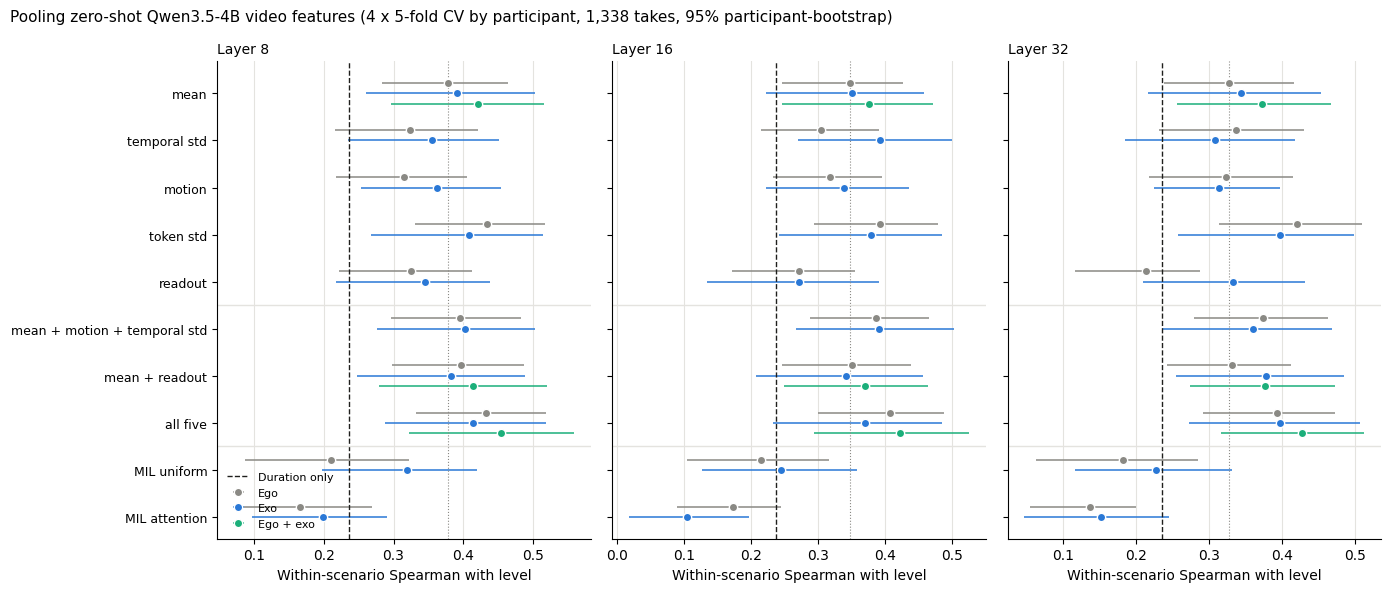

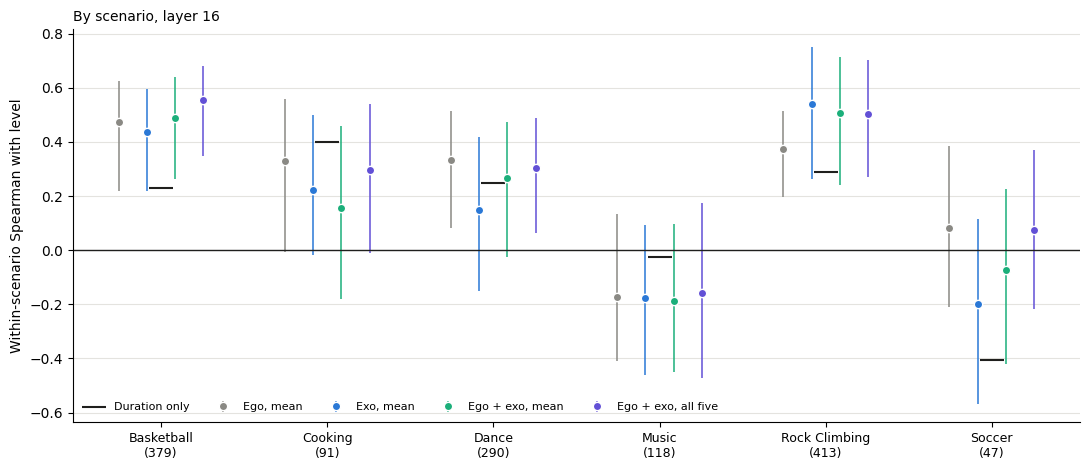

In [8]:
import matplotlib.pyplot as plt

VIEW_COLORS = {"ego": "#8a8984", "exo": "#2a78d6", "ego+exo": "#1baf7a"}
SCENARIO_COLORS = dict(zip(FIGURE_SCENARIO_KEYS, ("#8a8984", "#2a78d6", "#1baf7a", "#6250d6")))
GRID_COLOR, DARK = "#e4e3df", "#1f1f1d"

def style(ax, axis="x"):
    ax.grid(axis=axis, color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

# Figure 1: Spearman per representation, by view, one panel per layer.
fig, axes = plt.subplots(1, len(LAYER_LIST), figsize=(14, 6), sharey=True)
y = np.arange(len(ROW_NAMES))[::-1]
offsets = {"ego": 0.22, "exo": 0, "ego+exo": -0.22}
for ax, layer in zip(axes, LAYER_LIST):
    for view in (*VIEWS, "ego+exo"):
        rows = [(yy, spearman[k]) for yy, row in zip(y, ROW_NAMES) if (k := f"{view}, L{layer}: {row}") in spearman]
        if not rows:
            continue
        ys, values = zip(*rows)
        values = np.array(values)
        ax.errorbar(values[:, 0], np.array(ys) + offsets[view], xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                    ls="none", marker="o", ms=6, color=VIEW_COLORS[view], markeredgecolor="white", markeredgewidth=1,
                    elinewidth=1.1, label={"ego": "Ego", "exo": "Exo", "ego+exo": "Ego + exo"}[view])
    ax.axvline(spearman["duration only"][0], color=DARK, lw=1, ls="--", label="Duration only")
    ax.axvline(spearman[f"ego, L{layer}: mean"][0], color=VIEW_COLORS["ego"], lw=0.8, ls=":")
    ax.set_title(f"Layer {layer}", loc="left", fontsize=10)
    ax.set_xlabel("Within-scenario Spearman with level")
    for k in (len(BASE), len(BASE) + len(COMBOS)):
        ax.axhline(y[k - 1] - 0.5, color=GRID_COLOR, lw=1)
    style(ax)
axes[0].set_yticks(y, ROW_NAMES, fontsize=9)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(f"Pooling zero-shot Qwen3.5-4B video features ({N_REPEATS} x {N_FOLDS}-fold CV by participant, "
             f"{len(names):,} takes, 95% participant-bootstrap)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/pooling_representations.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: per scenario, ego vs exo vs both (layer 16).
fig, ax = plt.subplots(figsize=(11, 4.8))
xs = np.arange(len(SCENARIO_NAMES))
for k, (key, label) in enumerate(FIGURE_SCENARIO_KEYS.items()):
    values = np.array([scenario_ci[key, s] for s in SCENARIO_NAMES])
    ax.errorbar(xs + (k - 1.5) * 0.17, values[:, 0], yerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]], ls="none",
                marker="o", ms=6, color=SCENARIO_COLORS[key], markeredgecolor="white", markeredgewidth=1, elinewidth=1.1, label=label)
ax.scatter(xs, [by_scenario["duration only"][s] for s in SCENARIO_NAMES], marker="_", s=300, color=DARK, label="Duration only")
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(xs, [f"{s}\n({(scenarios == s).sum()})" for s in SCENARIO_NAMES], fontsize=9)
ax.set_ylabel("Within-scenario Spearman with level")
ax.set_title("By scenario, layer 16", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="lower left")
style(ax, "y")
fig.tight_layout()
fig.savefig("figures/pooling_scenarios.png", dpi=200, bbox_inches="tight")
plt.show()